# 문장 임베딩과 사용자 피드백 기반 학생 맞춤형 공지 및 복지 선별 알림 모델

- **타겟 페르소나**: 경희대학교 국제캠퍼스 소프트웨어융합학과 4학년 · 성남시 분당구 거주
- **핵심 파이프라인**:
  1. **수집·정규화 계약**: 7개 소스(`swcon` 학사/취업, `goodjob` 3개 게시판, `성남청년다해`, `온통청년 API`)에서 979건의 9컬럼 표준 스키마(`Canonical Schema`) 데이터 구축 (비로그인 원칙 ADR-02 준수)
  2. **한국어 전처리 및 EDA**: 정규식 정제 + `KoNLPy Okt` 형태소 분석 + 도메인 불용어 제거 + `TF-IDF` / `WordCloud`
  3. **Cold-Start 및 피드백 적응형 선별 모델**:
     - Baseline (`Exp 0`): `jhgan/ko-sroberta-multitask` 코사인 유사도 (`title@0.45`)
     - 단계적 개선 (`Exp 1` → `Exp 3b`): 입력/부정감점/임계값 튜닝 → 소량 `Rocchio` 보정 → 누적 피드백 `LogisticRegression` (vs `TF-IDF + LogReg` 대조군)
     - 최신 한국어 임베딩 1:1 비교 (`Exp 4a~4c`): `nlpai-lab/KURE-v1` (1024d) vs `ko-sroberta` (768d)
  4. **구조 인식 추출 요약 및 한국어 ROUGE 평가**: `TextRank` (Raw) vs `PreprocessedTextRankSummarizer` + 커스텀 한국어 `ROUGE-1 / ROUGE-L` (공백·Okt)
  5. **오류 분석 및 실행 가능성 검증**: Jira `버그`(`NTF-21`~`NTF-24`) 연동 오류 분석 + 오프라인 Discord 알림 카드 시연 + CPU 전용 `Restart & Run All` 완주


## 0. 환경 설정 및 재현성 초기화 (`CPU / CUDA` 자동 분기)


In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import StratifiedShuffleSplit
from wordcloud import WordCloud

# 노트북 실행 위치(notebooks/ 또는 루트)에 무관하게 저장소 루트 탐색
cwd = Path.cwd().resolve()
REPO_ROOT = cwd.parent if (cwd.name == "notebooks" and (cwd.parent / "src").is_dir()) else cwd
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.adapters.discord import format_notice_message
from src.config import get_device, load_profile
from src.eval.metrics import (
    evaluate_classification,
    evaluate_judge_agreement,
    evaluate_korean_rouge,
)
from src.models import (
    CosineProfileScorer,
    EmbeddingLogRegScorer,
    PreprocessedTextRankSummarizer,
    RocchioScorer,
    SentenceEmbedder,
    TextRankSummarizer,
    TfidfLogRegScorer,
    extract_texts_from_df,
)
from src.preprocess import clean_text, extract_okt_tfidf_keywords, load_stopwords, tokenize_okt
from src.preprocess.wordcloud_viz import find_korean_font_path
from src.schema import NoticeRecord

# 재현성 시드 및 디바이스(CPU / CUDA) 자동 선택
SEED = 42
np.random.seed(SEED)
DEVICE = get_device()
profile = load_profile()

# 한글 시각화 폰트 설정
try:
    import koreanize_matplotlib  # noqa: F401
except Exception:
    pass
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic")

print(f"REPO_ROOT : {REPO_ROOT}")
print(f"DEVICE    : {DEVICE}")
print(f"Target    : {profile['user']['university']} {profile['user']['major']} {profile['user']['grade']} ({profile['user']['region']})")


REPO_ROOT : C:\Users\LEE\notice-filter-nlp
DEVICE    : cpu
Target    : 경희대학교 국제캠퍼스 소프트웨어융합학과 4학년 (경기도 성남시 분당구)


## 1. 데이터셋 구성, 3-way 분할 및 LLM-as-a-Judge 신뢰도 검증


전체 수집 공지: 979건 | 5문장+ 장문 공지: 119건 (전처리 요약 대상 20건 추출)
분할 현황     : Train=729 (Pos 323) | Val=100 | Test Human Gold=150 (Pos 72 / Neg 78)
LLM Judge vs Human Gold (n=150): Accuracy = 0.8400 | Cohen's Kappa = 0.6785
Test Set 데이터 특성: 제목 절단(…) 비율 = 18.0% | 본문 부재(content='') 비율 = 72.7%


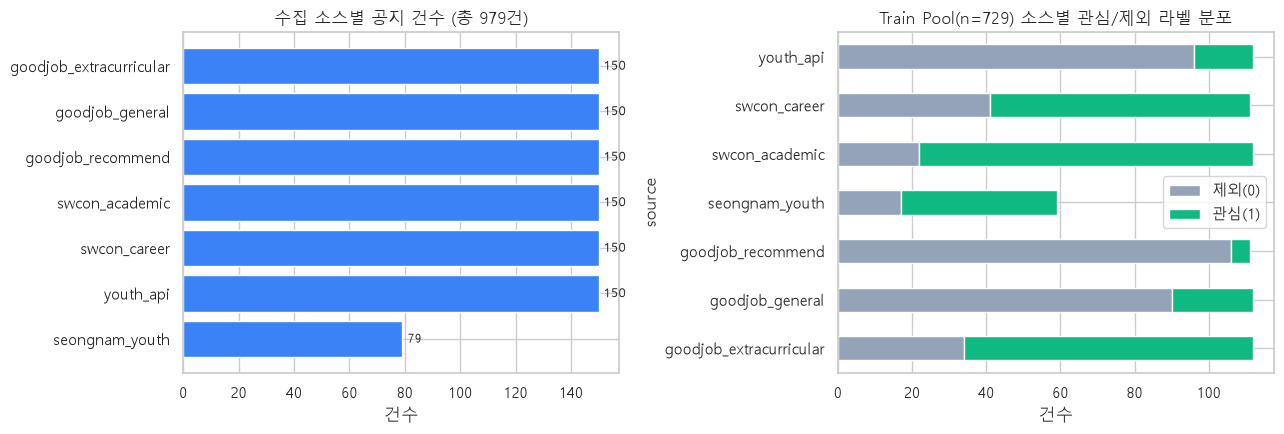

In [2]:
raw_df = pd.read_csv(REPO_ROOT / "data" / "raw_notices.csv", encoding="utf-8")
train_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "train.csv", encoding="utf-8")
val_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "val.csv", encoding="utf-8")
test_silver_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "test_with_silver.csv", encoding="utf-8")
test_gold_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "test_gold.csv", encoding="utf-8")
test_df = test_silver_df.merge(test_gold_df[["id", "human_label"]], on="id", how="inner")

sum_eval_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "summary_eval_20.csv", encoding="utf-8")
sum_gold_df = pd.read_csv(REPO_ROOT / "data" / "splits" / "summary_eval_gold.csv", encoding="utf-8")
sum_merged = sum_eval_df.merge(sum_gold_df[["id", "human_summary"]], on="id", how="inner")

y_gold = test_df["human_label"].astype(int).to_numpy()
y_silver = test_df["judge_label"].astype(int).to_numpy()
agreement = evaluate_judge_agreement(y_gold, y_silver)

trunc_rate = test_df["title"].fillna("").str.contains(r"\.\.|…", regex=True).mean()
empty_content_rate = (test_df["content"].fillna("").str.strip() == "").mean()

print(f"전체 수집 공지: {len(raw_df)}건 | 5문장+ 장문 공지: {(raw_df['content'].fillna('').apply(lambda s: len([x for x in str(s).split('.') if x.strip()]) >= 5)).sum()}건 (전처리 요약 대상 20건 추출)")
print(f"분할 현황     : Train={len(train_df)} (Pos {(train_df['judge_label']==1).sum()}) | Val={len(val_df)} | Test Human Gold={len(test_df)} (Pos {(y_gold==1).sum()} / Neg {(y_gold==0).sum()})")
print(f"LLM Judge vs Human Gold (n={len(test_df)}): Accuracy = {agreement['accuracy']:.4f} | Cohen's Kappa = {agreement['cohen_kappa']:.4f}")
print(f"Test Set 데이터 특성: 제목 절단(…) 비율 = {trunc_rate:.1%} | 본문 부재(content='') 비율 = {empty_content_rate:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
src_counts = raw_df["source"].value_counts()
axes[0].barh(src_counts.index[::-1], src_counts.values[::-1], color="#3B82F6")
axes[0].set_title("수집 소스별 공지 건수 (총 979건)")
axes[0].set_xlabel("건수")
for i, v in enumerate(src_counts.values[::-1]):
    axes[0].text(v + 2, i, str(v), va="center", fontsize=9)

ct = pd.crosstab(train_df["source"], train_df["judge_label"])
ct.columns = ["제외(0)", "관심(1)"]
ct.plot(kind="barh", stacked=True, color=["#94A3B8", "#10B981"], ax=axes[1])
axes[1].set_title("Train Pool(n=729) 소스별 관심/제외 라벨 분포")
axes[1].set_xlabel("건수")
plt.tight_layout()
plt.show()


## 2. 한국어 전처리 (`KoNLPy Okt`), `TF-IDF` 핵심 키워드 및 `WordCloud`


[전처리 예시] (youth_api) 청년놀이터·창업놀이터 운영
- 원문 일부 : 청년(예비) 창업자의 우수한 창업아이템 발굴․육성, 창업 초기 사업화 자금 지원을 통하여 청년 창업가들의 아이디어와 기술력을 사업화하고 지속 가능한 유망기업으로의 성장 기반 마련 1. 위탁사무명 : 청년놀이터․창업놀...
- 정제 결과 : 청년(예비) 창업자의 우수한 창업아이템 발굴 육성, 창업 초기 사업화 자금 지원을 통하여 청년 창업가들의 아이디어와 기술력을 사업화하고 지속 가능한 유망기업으로의 성장 기반 마련 1. 위탁사무명 : 청년놀이터 창업놀...
- Okt 명사  : ['청년', '예비', '창업', '자의', '창업', '아이템', '발굴', '육성', '창업', '초기', '자금', '청년', '창업가', '아이디어', '기술']


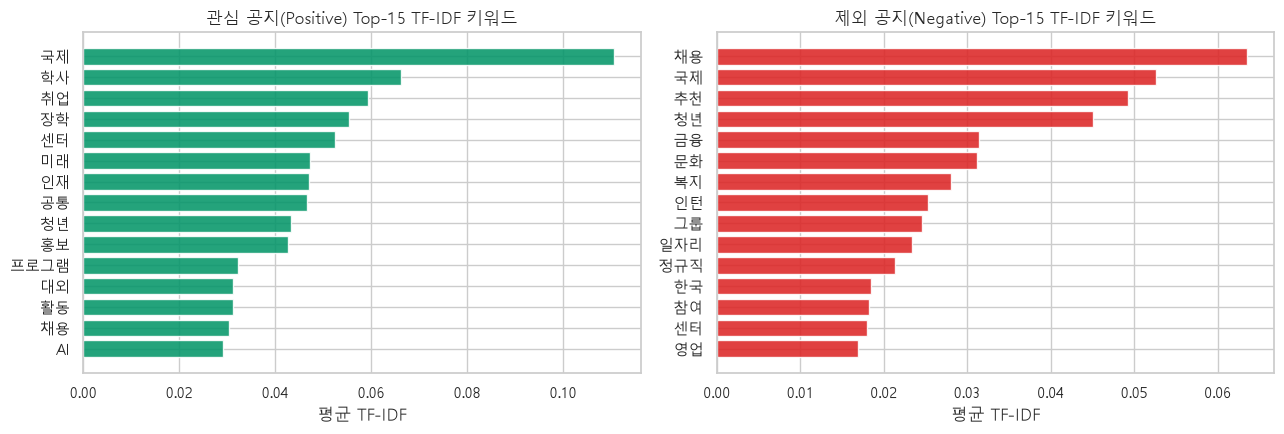

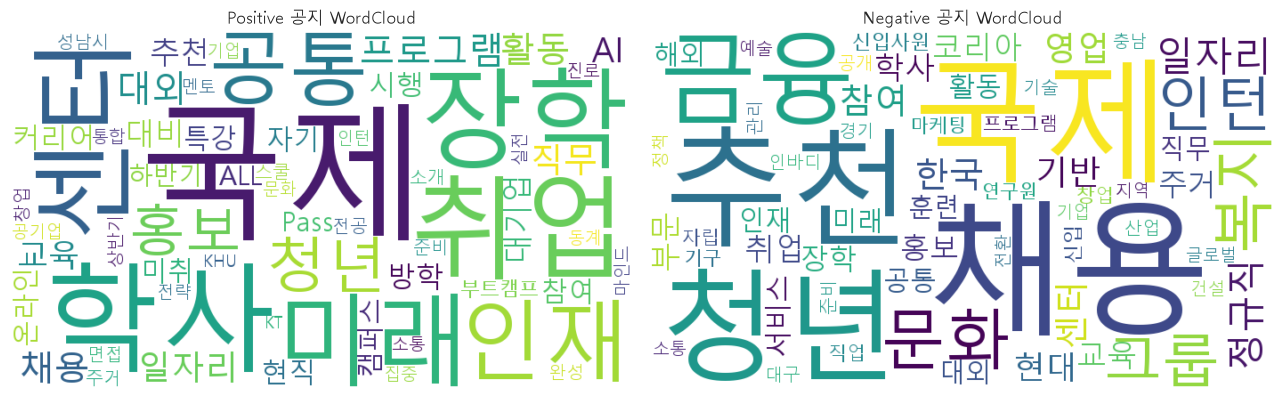

In [3]:
sample_row = train_df[train_df["content"].fillna("").str.len() > 200].iloc[0]
cleaned_sample = clean_text(sample_row["content"][:250])
tokens_sample = tokenize_okt(cleaned_sample, mode="nouns", stopwords=load_stopwords())
print(f"[전처리 예시] ({sample_row['source']}) {sample_row['title']}")
print(f"- 원문 일부 : {str(sample_row['content'])[:120]}...")
print(f"- 정제 결과 : {cleaned_sample[:120]}...")
print(f"- Okt 명사  : {tokens_sample[:15]}")

pos_texts = train_df[train_df["judge_label"] == 1].apply(lambda r: f"{r['category']} {r['title']}", axis=1).tolist()
neg_texts = train_df[train_df["judge_label"] == 0].apply(lambda r: f"{r['category']} {r['title']}", axis=1).tolist()

stopwords = load_stopwords()
pos_kw = extract_okt_tfidf_keywords(pos_texts, top_k=15, stopwords=stopwords)
neg_kw = extract_okt_tfidf_keywords(neg_texts, top_k=15, stopwords=stopwords)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, kw, title, color in (
    (axes[0], pos_kw, "관심 공지(Positive) Top-15 TF-IDF 키워드", "#059669"),
    (axes[1], neg_kw, "제외 공지(Negative) Top-15 TF-IDF 키워드", "#DC2626"),
):
    words = [k for k, _ in kw][::-1]
    scores = [s for _, s in kw][::-1]
    ax.barh(words, scores, color=color, alpha=0.88)
    ax.set_title(title)
    ax.set_xlabel("평균 TF-IDF")
plt.tight_layout()
plt.show()

font_path = find_korean_font_path()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, texts, title in (
    (axes[0], pos_texts, "Positive 공지 WordCloud"),
    (axes[1], neg_texts, "Negative 공지 WordCloud"),
):
    freq = dict(extract_okt_tfidf_keywords(texts, top_k=60, stopwords=stopwords))
    wc = WordCloud(font_path=font_path, width=700, height=400, background_color="white").generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. 단계적 선별 모델 비교 실험 (`Exp 0` ~ `Exp 4c`, `Hold-out Test n=150` Human Gold)

Validation Set(`val.csv`, n=100)에서 단독 튜닝 후 잠금(`val_tuned_config.json`)된 하이퍼파라미터를 그대로 적용해 **Hold-out Human Gold 150건**에 대해 한 번에 하나의 변수만 변경하며 비교합니다.
- 사전 계산 캐시(`data/embeddings/`)가 존재하면 즉시 로드하고, 캐시가 없는 환경에서는 `DEVICE` 설정에 따라 `CPU` 또는 `CUDA`에서 실시간 임베딩을 생성합니다.


,Experiment,Threshold,F1,Precision,Recall,Accuracy
0,Exp 0: Baseline (ko-sroberta title@0.45),0.45,0.6761,0.6857,0.6667,0.6933
1,Exp 1: Input/Thresh (full),0.37,0.7853,0.7033,0.8889,0.7667
2,"Exp 2: Rocchio (ko-sroberta, n=50)",0.51,0.7904,0.6947,0.9167,0.7667
3,Exp 3a: TF-IDF + LogReg (Control),0.50,0.7746,0.7857,0.7639,0.7867
4,Exp 3b: ko-sroberta + LogReg (n=729),0.35,0.8250,0.7500,0.9167,0.8133
5,Exp 4a: KURE-v1 Cosine,0.51,0.7665,0.6737,0.8889,0.7400
6,Exp 4b: KURE-v1 Rocchio (n=50),0.53,0.7561,0.6739,0.8611,0.7333
7,Exp 4c: KURE-v1 + LogReg (n=729),0.40,0.8125,0.7386,0.9028,0.8000


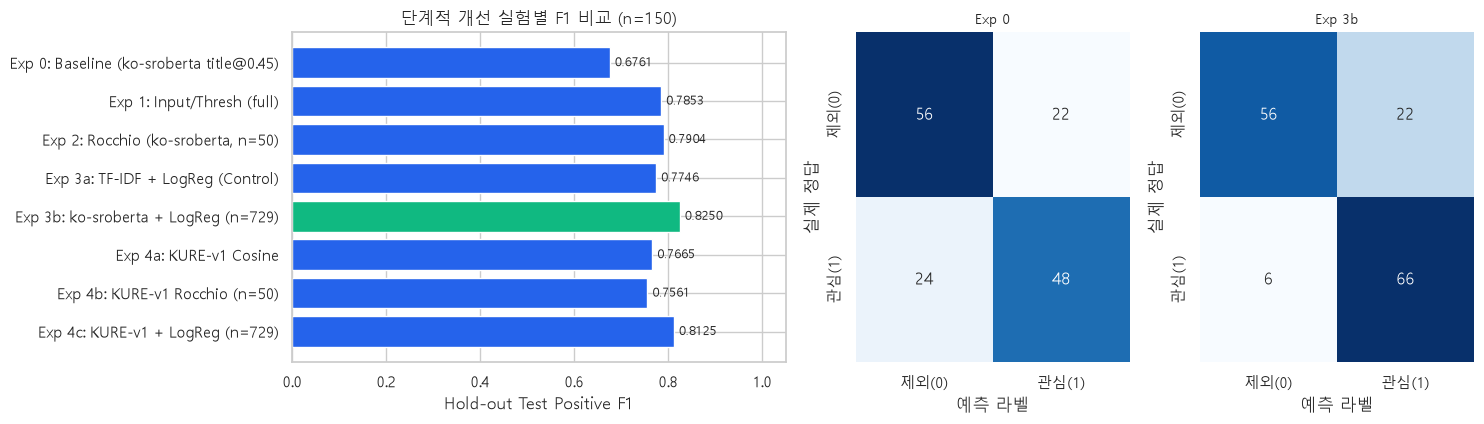

In [4]:
class CachedNotebookEmbedder:
    """캐시(.npy) 우선 조회 + 미캐시 시 SentenceEmbedder 실시간 인코딩(CPU/CUDA 자동 분기)."""

    def __init__(self, model_name: str, device: str, cache_dir: Path) -> None:
        self.model_name = model_name
        self.embedder = SentenceEmbedder(model_name=model_name, device=device, cache_dir=cache_dir)
        self._lookup: dict[str, np.ndarray] = {}
        self.batch_size = 16 if ("kure" in model_name.lower() or "bge" in model_name.lower()) else 64

    def preload(self, cache_key: str, texts: list[str]) -> None:
        vecs = self.embedder.encode_cached(cache_key, texts, batch_size=self.batch_size)
        for text, vec in zip(texts, vecs):
            self._lookup[str(text)] = np.asarray(vec, dtype=np.float32)

    def encode(self, texts: list[str], normalize: bool = True, batch_size: int = 32) -> np.ndarray:
        if not texts:
            return np.empty((0, 0), dtype=np.float32)
        missing = [str(t) for t in texts if str(t) not in self._lookup]
        if missing:
            encoded = self.embedder.encode(missing, normalize=normalize, batch_size=self.batch_size)
            for t, v in zip(missing, encoded):
                self._lookup[t] = np.asarray(v, dtype=np.float32)
        stacked = np.vstack([self._lookup[str(t)] for t in texts]).astype(np.float32)
        if normalize:
            norms = np.linalg.norm(stacked, axis=1, keepdims=True)
            stacked = np.divide(stacked, norms, out=np.zeros_like(stacked), where=norms > 0)
        return stacked


def sample_few_shot(df: pd.DataFrame, n_samples: int, seed: int = 42) -> pd.DataFrame:
    if n_samples >= len(df):
        return df.copy()
    splitter = StratifiedShuffleSplit(n_splits=1, train_size=n_samples, random_state=seed)
    idx, _ = next(splitter.split(df, df["judge_label"]))
    return df.iloc[idx].copy()


tuned_cfg = json.loads((REPO_ROOT / "results" / "val_tuned_config.json").read_text(encoding="utf-8"))
cache_dir = REPO_ROOT / "data" / "embeddings"
pos_q = list(profile["interests"]["positive_queries"])
neg_q = list(profile["interests"]["negative_queries"])

base_emb = CachedNotebookEmbedder(tuned_cfg["baseline_model"], DEVICE, cache_dir)
for mode in ("title", "meta_title", "full"):
    base_emb.preload(f"raw_{mode}_kosroberta", extract_texts_from_df(raw_df, mode))
base_emb.preload("profile_pos_kosroberta", pos_q)
base_emb.preload("profile_neg_kosroberta", neg_q)

modern_emb = CachedNotebookEmbedder(tuned_cfg["modern_model"], DEVICE, cache_dir)
for mode in ("meta_title", "full"):
    modern_emb.preload(f"raw_{mode}_modern", extract_texts_from_df(raw_df, mode))
modern_emb.preload("profile_pos_modern", pos_q)
modern_emb.preload("profile_neg_modern", neg_q)

best_mode = str(tuned_cfg["exp1"]["text_mode"])
train_texts = extract_texts_from_df(train_df, text_mode=best_mode)
train_labels = train_df["judge_label"].astype(int).tolist()
fb50_df = sample_few_shot(train_df, 50, SEED)
fb50_texts = extract_texts_from_df(fb50_df, text_mode=best_mode)
fb50_labels = fb50_df["judge_label"].astype(int).tolist()

experiments = [
    ("Exp 0: Baseline (ko-sroberta title@0.45)", CosineProfileScorer(base_emb, pos_q, text_mode="title"), 0.45),
    (
        f"Exp 1: Input/Thresh ({best_mode})",
        CosineProfileScorer(base_emb, pos_q, negative_queries=neg_q if tuned_cfg["exp1"]["use_neg"] else None, text_mode=best_mode, neg_weight=0.25),
        float(tuned_cfg["exp1"]["threshold"]),
    ),
    (
        "Exp 2: Rocchio (ko-sroberta, n=50)",
        RocchioScorer(base_emb, pos_q, alpha=tuned_cfg["exp2"]["alpha"], beta=tuned_cfg["exp2"]["beta"], text_mode=best_mode).fit(fb50_texts, fb50_labels),
        float(tuned_cfg["exp2"]["threshold"]),
    ),
    (
        "Exp 3a: TF-IDF + LogReg (Control)",
        TfidfLogRegScorer(c_value=tuned_cfg["exp3a"]["c_value"], text_mode=best_mode).fit(train_texts, train_labels),
        float(tuned_cfg["exp3a"]["threshold"]),
    ),
    (
        "Exp 3b: ko-sroberta + LogReg (n=729)",
        EmbeddingLogRegScorer(base_emb, c_value=tuned_cfg["exp3b"]["c_value"], text_mode=best_mode).fit(train_texts, train_labels),
        float(tuned_cfg["exp3b"]["threshold"]),
    ),
    (
        "Exp 4a: KURE-v1 Cosine",
        CosineProfileScorer(modern_emb, pos_q, negative_queries=neg_q if tuned_cfg["exp4a"]["use_neg"] else None, text_mode=best_mode, neg_weight=0.25),
        float(tuned_cfg["exp4a"]["threshold"]),
    ),
    (
        "Exp 4b: KURE-v1 Rocchio (n=50)",
        RocchioScorer(modern_emb, pos_q, alpha=tuned_cfg["exp4b"]["alpha"], beta=tuned_cfg["exp4b"]["beta"], text_mode=best_mode).fit(fb50_texts, fb50_labels),
        float(tuned_cfg["exp4b"]["threshold"]),
    ),
    (
        "Exp 4c: KURE-v1 + LogReg (n=729)",
        EmbeddingLogRegScorer(modern_emb, c_value=tuned_cfg["exp4c"]["c_value"], text_mode=best_mode).fit(train_texts, train_labels),
        float(tuned_cfg["exp4c"]["threshold"]),
    ),
]

eval_rows = []
pred_store = {}
for name, scorer, thr in experiments:
    scores = scorer.score(test_df)
    preds = (scores >= thr).astype(int)
    m = evaluate_classification(y_gold, preds)
    eval_rows.append({"Experiment": name, "Threshold": thr, "F1": m["f1"], "Precision": m["precision"], "Recall": m["recall"], "Accuracy": m["accuracy"], "CM": m["confusion_matrix"]})
    pred_store[name] = (scores, preds, m["confusion_matrix"])

res_df = pd.DataFrame(eval_rows)
display(res_df[["Experiment", "Threshold", "F1", "Precision", "Recall", "Accuracy"]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.8, 1.0, 1.0]})
bars = axes[0].barh(res_df["Experiment"][::-1], res_df["F1"][::-1], color=["#10B981" if "3b" in e else "#2563EB" for e in res_df["Experiment"][::-1]])
axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel("Hold-out Test Positive F1")
axes[0].set_title("단계적 개선 실험별 F1 비교 (n=150)")
for bar in bars:
    val = bar.get_width()
    axes[0].text(val + 0.01, bar.get_y() + bar.get_height() / 2, f"{val:.4f}", va="center", fontsize=8.5)

best_name = res_df.sort_values(["F1", "Accuracy"], ascending=False).iloc[0]["Experiment"]
for ax, key in ((axes[1], experiments[0][0]), (axes[2], best_name)):
    cm = np.array(pred_store[key][2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["제외(0)", "관심(1)"], yticklabels=["제외(0)", "관심(1)"])
    ax.set_xlabel("예측 라벨")
    ax.set_ylabel("실제 정답")
    ax.set_title(key.split(":")[0], fontsize=10)
plt.tight_layout()
plt.show()


## 4. 피드백 누적 규모별 학습 곡선 & 최신 임베딩 트레이드오프 분석

피드백 데이터 건수(`20` → `729`) 증가에 따른 성능 추이를 보면, **고차원(1024d) `KURE-v1`은 극소량 피드백 구간(`n=20~50`)에서 분산 증가로 과적합되는 반면, 768d `ko-sroberta + LogReg`는 `n >= 100`부터 TF-IDF를 추월해 최고 `F1=0.8250`을 달성**합니다.


n_feedback,20,50,100,200,400,729
model,,,,,,
KURE-v1 + LogReg,0.6486,0.6606,0.7232,0.7929,0.8050,0.8125
TF-IDF + LogReg,0.7815,0.7571,0.7770,0.8056,0.7801,0.7746
ko-sroberta + LogReg,0.6961,0.7403,0.7784,0.8323,0.8428,0.8250


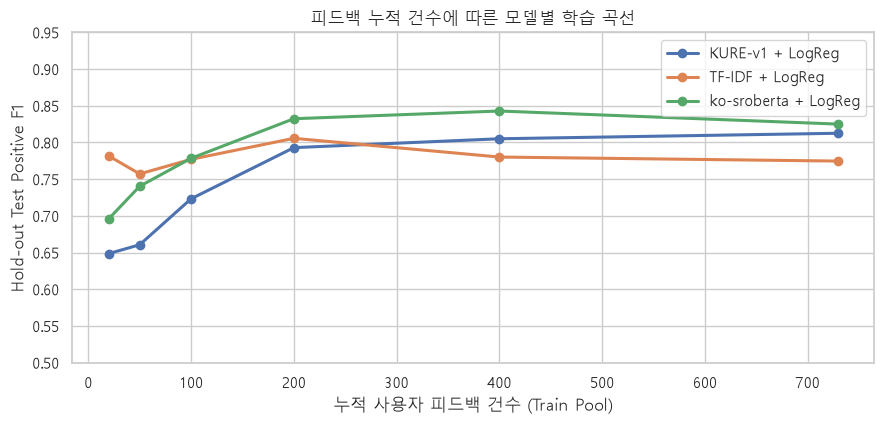

In [5]:
lc_rows = []
for n_fb in (20, 50, 100, 200, 400, len(train_df)):
    sub_df = sample_few_shot(train_df, n_fb, SEED)
    sub_texts = extract_texts_from_df(sub_df, text_mode=best_mode)
    sub_labels = sub_df["judge_label"].astype(int).tolist()
    for label_name, clf, thr in (
        ("TF-IDF + LogReg", TfidfLogRegScorer(c_value=tuned_cfg["exp3a"]["c_value"], text_mode=best_mode).fit(sub_texts, sub_labels), float(tuned_cfg["exp3a"]["threshold"])),
        ("ko-sroberta + LogReg", EmbeddingLogRegScorer(base_emb, c_value=tuned_cfg["exp3b"]["c_value"], text_mode=best_mode).fit(sub_texts, sub_labels), float(tuned_cfg["exp3b"]["threshold"])),
        ("KURE-v1 + LogReg", EmbeddingLogRegScorer(modern_emb, c_value=tuned_cfg["exp4c"]["c_value"], text_mode=best_mode).fit(sub_texts, sub_labels), float(tuned_cfg["exp4c"]["threshold"])),
    ):
        m = evaluate_classification(y_gold, clf.predict(test_df, threshold=thr))
        lc_rows.append({"n_feedback": n_fb, "model": label_name, "f1": round(m["f1"], 4), "accuracy": round(m["accuracy"], 4)})

lc_df = pd.DataFrame(lc_rows)
display(lc_df.pivot(index="model", columns="n_feedback", values="f1"))

fig, ax = plt.subplots(figsize=(9, 4.4))
for model_name, grp in lc_df.groupby("model"):
    ax.plot(grp["n_feedback"], grp["f1"], marker="o", linewidth=2.2, label=model_name)
ax.set_xlabel("누적 사용자 피드백 건수 (Train Pool)")
ax.set_ylabel("Hold-out Test Positive F1")
ax.set_title("피드백 누적 건수에 따른 모델별 학습 곡선")
ax.set_ylim(0.5, 0.95)
ax.legend()
plt.tight_layout()
plt.show()


## 5. 오류 분석 및 Jira `버그` 티켓 추적 (`NTF-21` ~ `NTF-24`)

- **NTF-21 (`FP`)**: `일반대학원`, `스포츠`, `AI-Native Sales` 등 표면 어휘(`AI`, `빅데이터`, `취업`)에 의한 오탐지 → 부정 감점 및 `LogReg` 학습으로 대폭 감소
- **NTF-22 (`FN`)**: `title` 전용 Cold-Start에서 `전세보증금`, `전ㆍ월세`, `학점포기` 공지 미탐지 → `full` 입력 + 임계값 튜닝(`FN 24 -> 8`) 및 `Exp 3b` (`FN 6`)로 해소
- **NTF-23 (`데이터 병목`)**: `goodjob` 목록 제목 `…` 절단(Test 18.0% / Exp 0 오분류의 26.1%) 및 비로그인 본문 부재(Test 72.7% / Exp 0 오분류의 73.9%)
- **NTF-24 (`요약 편향`)**: 행정 서류(`1부`, `성적증명서`) 단어 반복 편향 및 개조식 미분리 → `PreprocessedTextRankSummarizer`로 해결


In [6]:
exp0_scores, exp0_preds, _ = pred_store[experiments[0][0]]
best_scores, best_preds, _ = pred_store[best_name]

err_df = test_df[["id", "source", "category", "title", "content", "human_label"]].copy()
err_df["exp0_score"] = np.round(exp0_scores, 4)
err_df["exp0_pred"] = exp0_preds
err_df["best_pred"] = best_preds
err_only = err_df[err_df["exp0_pred"] != err_df["human_label"]].copy()
err_only["error_type"] = np.where(err_only["exp0_pred"] == 1, "FP", "FN")
err_only["resolved_by_exp3b"] = err_only["best_pred"] == err_only["human_label"]
err_only["is_truncated"] = err_only["title"].fillna("").str.contains(r"\.\.|…", regex=True)
err_only["no_content"] = err_only["content"].fillna("").str.strip() == ""

print(f"Exp 0 총 오분류: {len(err_only)}건 (FP={(err_only['error_type']=='FP').sum()}, FN={(err_only['error_type']=='FN').sum()})")
print(f"오분류 중 제목 절단 비율: {err_only['is_truncated'].mean():.1%} | 본문 부재 비율: {err_only['no_content'].mean():.1%}")
print(f"최종 모델(Exp 3b)로 구제된 Exp 0 오분류: {err_only['resolved_by_exp3b'].sum()} / {len(err_only)}건")

display(
    err_only[["id", "source", "error_type", "exp0_score", "human_label", "best_pred", "resolved_by_exp3b", "title"]].head(8)
)


Exp 0 총 오분류: 46건 (FP=22, FN=24)
오분류 중 제목 절단 비율: 26.1% | 본문 부재 비율: 73.9%
최종 모델(Exp 3b)로 구제된 Exp 0 오분류: 36 / 46건


,id,source,error_type,exp0_score,human_label,best_pred,resolved_by_exp3b,title
0,swcon_academic_536802,swcon_academic,FP,0.5553,0,1,False,[홍보] (국제)일반대학원] 2026학년도 가을 일반대학원 학과 및 연구실탐방 프로그램
2,goodjob_recommend_2091,goodjob_recommend,FP,0.4622,0,0,True,[큐에이드] 서비스 정책 기획 관리/서비스 자재 운영관…
3,swcon_career_552170,swcon_career,FP,0.6071,0,1,False,공통 [홍보] 경희대학교 국제캠퍼스 취업프로그램 홍보단 KHU Careers Edi...
9,swcon_academic_525209,swcon_academic,FN,0.4107,1,1,True,공통 2026학년도 1학기 휴학 신청 안내
12,goodjob_extracurricular_3715,goodjob_extracurricular,FN,0.3125,1,1,True,"[국제] <2026년, 기업은 이런 사람을 뽑는다: MBTI와 …"
14,seongnam_youth_biz_251,seongnam_youth,FN,0.3822,1,0,False,청춘남녀 만남행사「SOLO MON의 선택」25~26기 참가자 모집
15,goodjob_recommend_2074,goodjob_recommend,FP,0.4765,0,0,True,[아남전자(주)] 전략기획/경영기획(기획팀 신입) 정규…
17,goodjob_extracurricular_3707,goodjob_extracurricular,FN,0.3650,1,1,True,[국제] 2026년 상반기 대기업 지원 집중케어 1Day 자기소…


## 6. 추출 요약(`Raw TextRank` vs `PreprocessedTextRank`) 및 한국어 `ROUGE` (`n=20`)


,Summarizer,Tokenizer,ROUGE-1,ROUGE-L
0,Raw TextRank,space,0.3593,0.3482
1,PreprocessedTextRank,space,0.3873,0.3808
2,Raw TextRank,okt,0.4232,0.3802
3,PreprocessedTextRank,okt,0.4494,0.4173


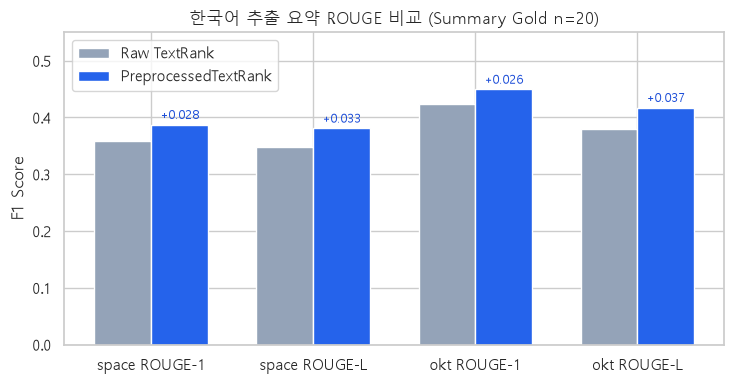


[정성 비교 1] [성남시청소년청년재단] 2026 청년의 시간 참가팀 모집
- Human Gold : 청년의 시간(청년 참여형 정책 포럼)」 참가팀을 모집합니다. 거창한 정책이나 어려운 이론이 아니어도 좋습니다. 청년의 시선에서 발견한 문제, 꼭 해보고 싶었던 활동, 다른 청년들과 함께하고 싶은 프로그램까지! 3~6명의 청년이 팀을 이루어 아이디어를 
- Raw        : *** 해당 사업은 성남 청년정보 플랫폼이 아닌, 아래 적힌 이메일에 직접 접수해 주세요. 청년의 아이디어가 실제 사업으로 이어지는 시간, 지금 도전하세요! ■ 모집 및 운영 개요 - 모집기간 : 2026. 10. 30.(금) 09:00 ~ 11. 2
- Preprocessed: 해당 사업은 성남 청년정보 플랫폼이 아닌, 아래 적힌 이메일에 직접 접수해 주세요. 시상 규모 총 시상금 400만 원 / 총 10팀 시상 - 대상(1팀): 100만 원 - 최우수상(1팀): 80만 원 - 우수상(2팀): 각 50만 원 - 장려상(6팀)

[정성 비교 2] [성남시청소년청년재단] <성남청년 AI캠프> 참가자(교육생) 모집
- Human Gold : 성남 청년정보 플랫폼에서 신청하신 건은 접수되지 않습니다.* 급변하는 기업 현장의 'AI 퍼스트' 트렌드에 발맞추어, 성남 청년들의 실무형 AI 기술 융합 역량을 강화하고 안정적인 커리어 자립을 지원하는 「성남청년 AI 캠프」와 함께 할 참가자를 모집
- Raw        : *해당 사업은 성남 청년정보 플랫폼이 아닌, 온라인 신청서(https://forms.gle/mBtXfbxozpyVfw2H6)에 직접 접수해 주세요. 성남 청년정보 플랫폼에서 신청하신 건은 접수되지 않습니다.* 급변하는 기업 현장의 'AI 퍼스트' 트렌
- Preprocessed: 성남 청년정보 플랫폼에서 신청하신 건은 접수되지 않습니다.* 급변하는 기업 현장의 'AI 퍼스트' 트렌드에 발맞추어, 성남 청년들의 실무형 AI 기술 융합 역량을 강화하고 안정적인 커리어 자립을 지원하

In [7]:
raw_summarizer = TextRankSummarizer(top_k=3, min_sentences=5)
prep_summarizer = PreprocessedTextRankSummarizer(top_k=3, min_sentences=5)

contents = [str(t) for t in sum_merged["content"].fillna("")]
refs = [str(r) for r in sum_merged["human_summary"].fillna("")]
raw_preds = [raw_summarizer.summarize(t) for t in contents]
prep_preds = [prep_summarizer.summarize(t) for t in contents]

raw_space = evaluate_korean_rouge(refs, raw_preds, tokenizer="space")
raw_okt = evaluate_korean_rouge(refs, raw_preds, tokenizer="okt")
prep_space = evaluate_korean_rouge(refs, prep_preds, tokenizer="space")
prep_okt = evaluate_korean_rouge(refs, prep_preds, tokenizer="okt")

rouge_table = pd.DataFrame(
    [
        {"Summarizer": "Raw TextRank", "Tokenizer": "space", "ROUGE-1": raw_space["rouge1"], "ROUGE-L": raw_space["rougeL"]},
        {"Summarizer": "PreprocessedTextRank", "Tokenizer": "space", "ROUGE-1": prep_space["rouge1"], "ROUGE-L": prep_space["rougeL"]},
        {"Summarizer": "Raw TextRank", "Tokenizer": "okt", "ROUGE-1": raw_okt["rouge1"], "ROUGE-L": raw_okt["rougeL"]},
        {"Summarizer": "PreprocessedTextRank", "Tokenizer": "okt", "ROUGE-1": prep_okt["rouge1"], "ROUGE-L": prep_okt["rougeL"]},
    ]
)
display(rouge_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4.0))
labels = ["space ROUGE-1", "space ROUGE-L", "okt ROUGE-1", "okt ROUGE-L"]
raw_vals = [raw_space["rouge1"], raw_space["rougeL"], raw_okt["rouge1"], raw_okt["rougeL"]]
prep_vals = [prep_space["rouge1"], prep_space["rougeL"], prep_okt["rouge1"], prep_okt["rougeL"]]
x = np.arange(len(labels))
w = 0.35
ax.bar(x - w / 2, raw_vals, width=w, label="Raw TextRank", color="#94A3B8")
ax.bar(x + w / 2, prep_vals, width=w, label="PreprocessedTextRank", color="#2563EB")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 0.55)
ax.set_ylabel("F1 Score")
ax.set_title("한국어 추출 요약 ROUGE 비교 (Summary Gold n=20)")
ax.legend()
for idx, (rv, pv) in enumerate(zip(raw_vals, prep_vals)):
    ax.text(idx + w / 2, pv + 0.01, f"+{pv-rv:.3f}", ha="center", fontsize=8.5, color="#1D4ED8")
plt.tight_layout()
plt.show()

for i in range(2):
    print(f"\n[정성 비교 {i+1}] {sum_merged.iloc[i]['title']}")
    print(f"- Human Gold : {refs[i][:140]}")
    print(f"- Raw        : {raw_preds[i][:140]}")
    print(f"- Preprocessed: {prep_preds[i][:140]}")


## 7. End-to-End 추론 및 오프라인 Discord 알림 페이로드 시연


In [8]:
demo_candidates = test_df.copy()
demo_candidates["pred_score"] = best_scores
top3 = demo_candidates[demo_candidates["content"].fillna("").str.len() > 80].sort_values("pred_score", ascending=False).head(3)

for _, row in top3.iterrows():
    notice = NoticeRecord(
        id=str(row["id"]),
        source=str(row["source"]),
        category=str(row["category"]),
        title=str(row["title"]),
        meta_tags=str(row["meta_tags"] if pd.notna(row["meta_tags"]) else ""),
        posted_at=str(row["posted_at"] if pd.notna(row["posted_at"]) else ""),
        url=str(row["url"]),
        content=str(row["content"] if pd.notna(row["content"]) else ""),
        deadline=str(row["deadline"] if pd.notna(row["deadline"]) else ""),
    )
    summary = prep_summarizer.summarize(notice.content)
    payload = format_notice_message(notice, score=float(row["pred_score"]), summary=summary)
    print("=" * 72)
    print(f"[{payload['author']['name']}] {payload['title']} (Gold={row['human_label']})")
    print(payload["description"])
    print(" | ".join(f"{f['name']}: {f['value']}" for f in payload["fields"]))
    print(f"Footer: {payload['footer']['text']}")


[🏛️ 성남청년다해 · 참여소통] [야탑 유스센터] AI 취업역량 강화 특강 참여자 모집 (Gold=1)
• 해당 사업은 성남 청년정보 플랫폼이 아닌, 아래 적힌 신청폼 링크에 직접 접수해 주세요.
• AI 역량검사부터 AI 영상면접까지!
• 이번 특강에서는 AI 기반 면접 시스템을 이해하고, 면접에 필요한 시선·표정·발음·속도부터 예상 질문과 답변 STAR 구조까지 직접 연습해 볼 수 있습니다.

🏷️ `성남시` `참여소통` `단순접수형`
📌 출처: 🏛️ 성남청년다해 | 🎯 적합도: 🟢 96% (높음) | ⏰ 마감일: 2026-10-23 (마감)
Footer: 게시일: 2026-10-14 · ID: seongnam_youth_biz_279
[🎓 SW융합 학사/장학 · 학사/장학] 공통 [안내] 2026학년도 2학기 미분적분학 및 선형대수 추가 수강신청 (Gold=1)
관련근거: 응용과학대학-1353(2026.08.06)"2026학년도 2학기 미분적분학 및 선형대수 수강신청" 1) 수강대상 선정 및 연락: 2026.09.04.(금) 입력한 이메일로 연락(예정 2) 수강신청 등록: 2026.09.04.(금) 행정실에서 일괄 입력(예정

🏷️ `국제캠퍼스` `소프트웨어융합학과`
📌 출처: 🎓 SW융합 학사/장학 | 🎯 적합도: 🟢 92% (높음) | ⏰ 마감일: 2026-09-04 (마감)
Footer: 게시일: 2026-09-01 · ID: swcon_academic_551494
[💡 SW융합 취업/대외활동 · KG카이로스] [KG카이로스] 2기 모집 (Gold=0)
• AI 로봇 교육 KG-KAIROS 2기 모집(~6/9) 100%전액지원 훈련장려금 장학금 취업지원 취업컨설팅 자격증2종 KG ICT에서 국비교육 과정에 참여할 훈련생을 모집 중입니다.
• 1기 교육이 성공적으로 마무리되어 가고 있으며, 이에 따라 2기 훈련생을 모집하고 있습니다.

🏷️ `국제캠퍼스` `소프트웨어융합학과`
📌 출처: 💡 SW융합 취업/대외활동 | 🎯 적합도: 🟢 92% (높음) 

## 8. 결론 및 향후 발전 방향

1. **Cold-Start에서 적응형 개인화까지의 검증**: 프로필 코사인 유사도 기반 Baseline(`Exp 0`, `F1=0.6761`)에서 `full` 입력·부정 감점(`0.7853`) → 소량 `Rocchio`(`0.7904`) → 누적 피드백 `ko-sroberta + LogReg`(**`F1=0.8250`, `Accuracy=0.8133`**)까지 `+0.1489 F1`의 단계적 향상을 150건 Human Gold로 입증했습니다.
2. **모델 크기보다 도메인·입력 적합성**: 최신 1024d `KURE-v1`은 소량 피드백 구간에서 고차원 과적합을 보이며 최종 `F1=0.8125`에 머물러, 짧은 제목 중심 데이터에서는 `ko-sroberta`가 더 안정적임을 확인했습니다.
3. **실데이터 오류 기반 요약 개선**: 실제 Discord 전송에서 발견된 제출서류 체크리스트 편향과 개조식 미분리 문제를 `PreprocessedTextRankSummarizer`로 해결해 20건 기준 **Okt ROUGE-L `+0.0370`**(`0.3802 -> 0.4173`) 향상을 달성했습니다.
4. **향후 고도화(Future Work)**: 명백한 타지역·타분야 키워드는 1차 **규칙 기반 Hard Filter**로 선제 제거하고 모호한 공지 판별에만 임베딩 **Soft Filter**를 집중시키는 2단계 하이브리드 파이프라인으로 확장할 수 있습니다.
